# EDA

In [1]:
from pathlib import Path
import hashlib
import json
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = False

## Что лежит в файле

In [2]:
paths = [Path("data/hw1_train.jsonl"), Path("hw1_train.jsonl"), Path("../data/hw1_train.jsonl")]
DATA_PATH = next((p for p in paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Положите hw1_train.jsonl рядом с ноутбуком или в папку data/")

df = pd.read_json(DATA_PATH, lines=True)
print("Файл:", DATA_PATH)
print("Размер датасета:", df.shape)
print("Названия столбцов:", df.columns.tolist())

# посмотрим на структуру первой записи
example = df.iloc[0]
print("\nПример:")
print("ID:", example["dialog_id"])
print("Язык:", example["language"])
print("Количество реплик пользователя:", example["n_user_turns"])
print("Роли первых сообщений:", [t["role"] for t in example["turns"][:4]])
print("Поля labels:", list(example["labels"].keys()) if isinstance(example["labels"], dict) else None)

Файл: data/hw1_train.jsonl
Размер датасета: (10000, 5)
Названия столбцов: ['dialog_id', 'language', 'n_user_turns', 'turns', 'labels']

Пример:
ID: d094012177e
Язык: en
Количество реплик пользователя: 7
Роли первых сообщений: ['user', 'assistant', 'user', 'assistant']
Поля labels: ['task_type', 'reaction', 'user_turns']


`turns` — список реплик с ролями и текстами. метки существуют не для каждого диалога

In [26]:
# Метки вынесем в отдельные столбцы, чтобы не писать .get() в каждой ячейке.
df["reaction"] = df["labels"].apply(lambda x: x.get("reaction") if isinstance(x, dict) else None)
df["task_type"] = df["labels"].apply(lambda x: x.get("task_type") if isinstance(x, dict) else None)

print("Языки:")
display(df["language"].value_counts().to_frame("Число диалогов"))
print("\nИтоговые реакции:")
display(df["reaction"].fillna("не размечено").value_counts().to_frame("Число диалогов"))
print("\nПовторяющиеся ID:", df["dialog_id"].duplicated().sum())
print("Отсутствующих:", df["turns"].isna().sum())

Языки:


,Число диалогов
language,
en,9929
ru,71



Итоговые реакции:


,Число диалогов
reaction,
не размечено,7000
neutral,1774
negative,923
positive,303



Повторяющиеся ID: 0
Отсутствующих: 0


## Структура диалогов

В каждом диалоге должно быть столько ответов модели, сколько сообщений пользователя - проверим

In [27]:
df["n_turns"] = df["turns"].apply(len)
df["n_user_actual"] = df["turns"].apply(lambda turns: sum(t["role"] == "user" for t in turns))
df["n_assistant_actual"] = df["turns"].apply(lambda turns: sum(t["role"] == "assistant" for t in turns))

def correct_roles(turns):
    return [t["role"] for t in turns] == ["user", "assistant"] * (len(turns) // 2)

print("Не совпадает n_user_turns с числом user-реплик:",
      (df["n_user_turns"] != df["n_user_actual"]).sum())
print("Не поровну user/assistant:",
      (df["n_user_actual"] != df["n_assistant_actual"]).sum())
print("Неверный порядок ролей:", (~df["turns"].apply(correct_roles)).sum())
print("\nРаспределение числа пользовательских сообщений:")
display(df["n_user_actual"].value_counts().sort_index().to_frame("Число диалогов"))

df["n_user_actual"].describe()

Не совпадает n_user_turns с числом user-реплик: 0
Не поровну user/assistant: 0
Неверный порядок ролей: 0

Распределение числа пользовательских сообщений:


,Число диалогов
n_user_actual,
5,3057
6,2325
7,1632
8,1292
9,947
10,747


count    10000.000000
mean         6.698800
std          1.595347
min          5.000000
25%          5.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: n_user_actual, dtype: float64

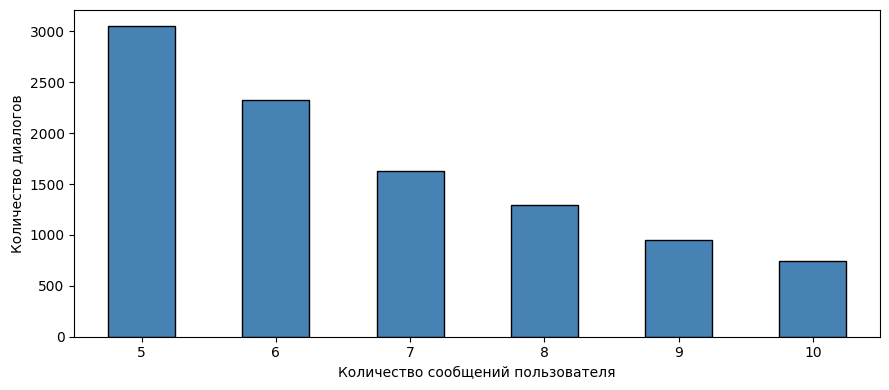

In [5]:
df["n_user_actual"].value_counts().sort_index().plot.bar(edgecolor="black", color="steelblue")
plt.xlabel("Количество сообщений пользователя")
plt.ylabel("Количество диалогов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Длины сообщений и диалогов

Посчитаем символы отдельно у пользователя и у ассистента. Для длинных диалогов среднее может сильно отличаться от медианы, поэтому смотрим и на квантили.

In [6]:
df["user_text"] = df["turns"].apply(lambda turns: "\n".join(t["text"] for t in turns if t["role"] == "user"))
df["assistant_text"] = df["turns"].apply(lambda turns: "\n".join(t["text"] for t in turns if t["role"] == "assistant"))
df["user_chars"] = df["turns"].apply(lambda turns: sum(len(t["text"]) for t in turns if t["role"] == "user"))
df["assistant_chars"] = df["turns"].apply(lambda turns: sum(len(t["text"]) for t in turns if t["role"] == "assistant"))
df["total_chars"] = df["user_chars"] + df["assistant_chars"]

print("Длина в символах:")
display(df[["user_chars", "assistant_chars", "total_chars"]].describe(percentiles=[.5, .9, .95, .99]).round(1))
print("\nДоля символов ассистента:",
      round(df["assistant_chars"].sum() / df["total_chars"].sum() * 100, 1), "%")

Длина в символах:


,user_chars,assistant_chars,total_chars
count,10000.0,10000.0,10000.0
mean,2339.6,9976.0,12315.6
std,3819.3,6758.6,8411.3
min,43.0,18.0,181.0
50%,914.0,8912.0,10800.5
90%,5932.4,19054.7,22333.9
95%,9422.0,22356.1,27614.1
99%,19381.1,30035.6,41245.1
max,42987.0,54682.0,59794.0



Доля символов ассистента во всём корпусе: 81.0 %


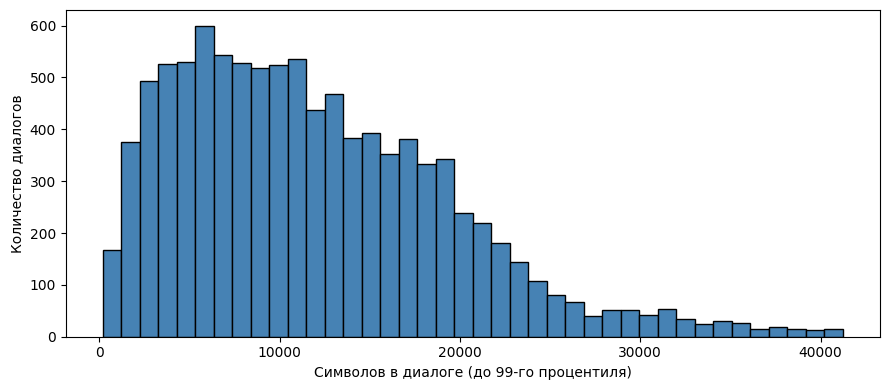

Диалогов за пределами графика: 100


In [7]:
# не будем удалять выбросы, ограничим только масштаб графика 99-м процентилем
limit = df["total_chars"].quantile(0.99)
plt.hist(df.loc[df["total_chars"] <= limit, "total_chars"],
         bins=40, edgecolor="black", color="steelblue")
plt.xlabel("Символов в диалоге (до 99-го процентиля)")
plt.ylabel("Количество диалогов")
plt.tight_layout()
plt.show()

print("Диалогов за пределами графика:", (df["total_chars"] > limit).sum())

несколько очень больших переписок влияют на среднее

посмотрим примеры длинных пользовательских сообщений, тк это может быть мусор, а может быть нормальный запрос с кодом/большим документом

In [29]:
longest = df.nlargest(5, "user_chars")
display(longest[["dialog_id", "language", "n_user_actual", "user_chars",
                 "assistant_chars", "reaction"]])

for _, row in longest.head(3).iterrows():
    first_long = max((t["text"] for t in row["turns"] if t["role"] == "user"), key=len)
    print(f"\n{row['dialog_id']}: длинное сообщение пользователя — {len(first_long)} символов")
    print("Начало:", repr(first_long[:180]))

,dialog_id,language,n_user_actual,user_chars,assistant_chars,reaction
1989,d97c8861e99,en,6,42987,14633,neutral
8808,d50f69f92ae,en,9,40714,3646,None
2423,d7bc62acd10,en,6,40659,15664,neutral
8141,d276a7d3769,en,10,39483,4908,None
688,d5117344965,en,6,39300,18172,neutral



d97c8861e99: длинное сообщение пользователя — 10885 символов
Начало: 'Here is part 2 Please wait for part 3\nPart 2:\nprivate void GroundCheck()\n{\nfloat maxDistance = 0.75f;\nif (Physics.Raycast(direction: new Vector3(0f, -1f), origin: raycastTr.positio'

d50f69f92ae: длинное сообщение пользователя — 7136 символов
Начало: 'System: You are a real estate chatbot and your job is to help your User sell a home. \n\nIf the User wants to sell now, your goal is to convince them to sign a listing agreement\nIf t'

d7bc62acd10: длинное сообщение пользователя — 13469 символов
Начало: 'Can we control even more parameters related to the networks in the updated code: import torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom torch.nn.utils.rnn import p'


## Метки реакции и дисбаланс

рассматриваем только размеченные диалоги

Размеченных диалогов: 3000
Неразмеченных: 7000


,Количество,"Доля, %"
reaction,,
negative,923,30.8
neutral,1774,59.1
positive,303,10.1


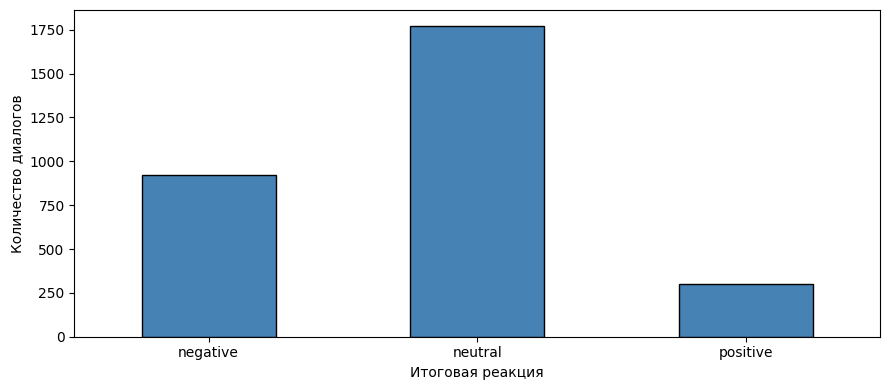

In [9]:
labeled = df[df["reaction"].notna()].copy()
print("Размеченных диалогов:", len(labeled))
print("Неразмеченных:", len(df) - len(labeled))

reaction_stats = labeled["reaction"].value_counts().reindex(
    ["negative", "neutral", "positive"], fill_value=0
)
display(pd.DataFrame({
    "Количество": reaction_stats,
    "Доля, %": (reaction_stats / len(labeled) * 100).round(1),
}))

reaction_stats.plot.bar(color="steelblue", edgecolor="black")
plt.xlabel("Итоговая реакция")
plt.ylabel("Количество диалогов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

поскольку классы различаются по размерам, одной accuracy для сравнения будущих моделей будет недостаточно. на этапе обучения понадобится отдельно оценивать качество по каждому классу и использовать macro-F1

In [31]:
print("Типы задач среди размеченных диалогов:")
display(labeled["task_type"].value_counts().to_frame("Число диалогов"))

print("\nРаспределение реакций внутри каждого типа задачи, %:")
display((pd.crosstab(labeled["task_type"], labeled["reaction"],
                     normalize="index") * 100).round(1))

print("\nЯзык и реакция:")
display(pd.crosstab(labeled["language"], labeled["reaction"]))

Типы задач среди размеченных диалогов:


,Число диалогов
task_type,
information_seeking,1831
creation,944
analysis,137
open-ended_discovery,88



Распределение реакций внутри каждого типа задачи, %:


reaction,negative,neutral,positive
task_type,,,
analysis,42.3,44.5,13.1
creation,23.6,68.9,7.5
information_seeking,34.4,55.7,9.9
open-ended_discovery,14.8,48.9,36.4



Язык и реакция:


reaction,negative,neutral,positive
language,,,
en,916,1760,302
ru,7,14,1


сравним ещё длины для разных классов

n_user_actual      user_chars         assistant_chars           \
                median mean     median    mean          median     mean   
reaction                                                                  
negative           6.0  6.7     1221.0  2754.1          9284.0  10095.9   
neutral            6.0  6.6      861.0  2308.8          9136.0  10421.6   
positive           7.0  6.9      840.0  2055.2          7172.0   8769.2   

         total_chars           
              median     mean  
reaction                       
negative     11580.0  12849.9  
neutral      11179.5  12730.4  
positive      9168.0  10824.4

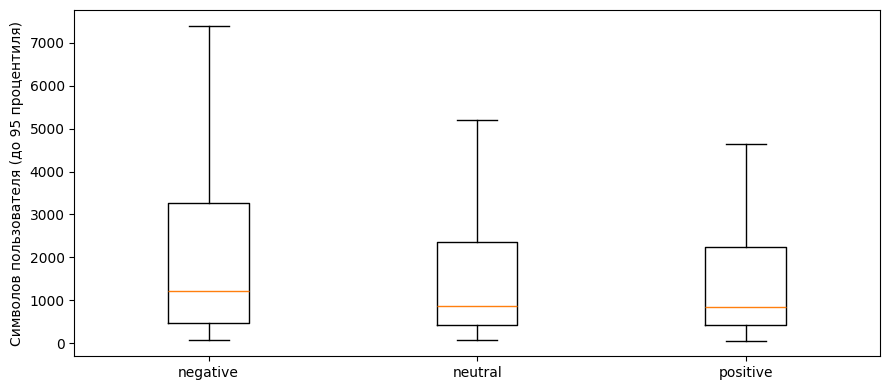

In [32]:
display(labeled.groupby("reaction")[["n_user_actual", "user_chars", "assistant_chars", "total_chars"]]
        .agg(["median", "mean"]).round(1))

reaction_order = ["negative", "neutral", "positive"]
plt.boxplot([labeled.loc[labeled["reaction"] == c, "user_chars"].clip(
                upper=labeled["user_chars"].quantile(0.95)) for c in reaction_order],
            tick_labels=reaction_order, showfliers=False)
plt.ylabel("Символов пользователя (до 95 процентиля)")
plt.tight_layout()
plt.show()

## Исследуем разметку данных

В `labels` есть не только итоговая реакция: у каждой пользовательской реплики записаны `state`, `task_type`, `reaction` и иногда `reaction_reason`. Проверим их заполненность и согласованность. Это анализ разметки, а не признаки для классификатора

In [37]:
labeled["n_turn_labels"] = labeled["labels"].apply(lambda x: len(x.get("user_turns", [])))
print("Количество пользовательских сообщений не совпадает с количеством записей о них:",
      (labeled["n_turn_labels"] != labeled["n_user_actual"]).sum())

turn_labels = pd.DataFrame([
    {"dialog_id": row["dialog_id"], "final_reaction": row["reaction"], **turn_label}
    for _, row in labeled.iterrows()
    for turn_label in row["labels"].get("user_turns", [])
])
print("Реплик с метками:", len(turn_labels))
for field in ["state", "task_type", "reaction", "reaction_reason"]:
    print(f"\n{field}:")
    display(turn_labels[field].fillna("нет значения").value_counts().head(15).to_frame("Частота"))

Количество пользовательских сообщений не совпадает с количеством записей о них: 0
Реплик с метками: 20051

state:


,Частота
state,
continuation,10190
newtopic,5690
refinement,2571
feedback,1577
positive_closure,21
revision,2



task_type:


,Частота
task_type,
information_seeking,11582
creation,6284
analysis,1310
open-ended_discovery,875



reaction:


,Частота
reaction,
neutral,14099
нет значения,3000
negative,2416
positive,536



reaction_reason:


,Частота
reaction_reason,
нет значения,17108
Insufficient_Detail,853
Revision,491
Factual_Error,490
Negative_Feedback,283
Gratitude,188
Ignored,137
Acknowledgment,97
Style,71


In [38]:
# реакция последней реплики и последняя явно указанная реакция
def last_turn_reaction(labels):
    turns = labels.get("user_turns", [])
    return turns[-1].get("reaction") if turns else None

def last_known_reaction(labels):
    turns = labels.get("user_turns", [])
    return next((turn.get("reaction") for turn in reversed(turns)
                 if turn.get("reaction") is not None), None)

labeled["last_reaction"] = labeled["labels"].apply(last_turn_reaction)
labeled["last_known_reaction"] = labeled["labels"].apply(last_known_reaction)

print("Итоговая реакция * реакция последней пользовательской реплики:")
display(pd.crosstab(labeled["reaction"],
                    labeled["last_reaction"], dropna=False))
print("Совпадает итоговая реакция с последней:",
      round((labeled["reaction"] == labeled["last_reaction"]).mean() * 100, 1), "%")

print("\nИтоговая реакция * последняя НЕпустая реакция:")
display(pd.crosstab(labeled["reaction"],
                    labeled["last_known_reaction"], dropna=False))

Итоговая реакция * реакция последней пользовательской реплики:


last_reaction,negative,neutral,positive
reaction,,,
negative,517,406,0
neutral,0,1774,0
positive,0,167,136


Совпадает итоговая реакция с последней: 80.9 %

Итоговая реакция * последняя НЕпустая реакция:


last_known_reaction,negative,neutral,positive
reaction,,,
negative,517,406,0
neutral,0,1774,0
positive,0,167,136


совпадение итоговой и последней реакции — не правило корректности меток. итог может учитывать весь разговор: например, последняя реплика нейтральна, а раньше пользователь жаловался. 

In [14]:
# посмотрим, насколько часто внутри одного диалога вообще встречаются разные реакции
def reactions_in_dialog(labels):
    return set(t.get("reaction") for t in labels.get("user_turns", []) if t.get("reaction") is not None)

labeled["reactions_in_turns"] = labeled["labels"].apply(reactions_in_dialog)
labeled["n_reaction_types"] = labeled["reactions_in_turns"].apply(len)
print("Количество разных реакций внутри диалога:")
display(labeled["n_reaction_types"].value_counts().sort_index().to_frame("Число диалогов"))

print("\nПримеры, где последняя и итоговая реакции не совпадают:")
examples = labeled[labeled["reaction"] != labeled["last_reaction"]].head(5)
display(examples[["dialog_id", "reaction", "last_reaction", "n_user_actual"]])

Количество разных реакций внутри диалога:


,Число диалогов
n_reaction_types,
1,1870
2,1058
3,72



Примеры, где последняя и итоговая реакции не совпадают:


,dialog_id,reaction,last_reaction,n_user_actual
0,d094012177e,positive,neutral,7
4,d7a6280ce8e,negative,neutral,8
6,d6dbef1f003,negative,neutral,7
10,d61b201ed5c,negative,neutral,10
30,df2796b6898,negative,neutral,8


## Пустые сообщения и вставки кода

Для вставок кода проверяем пользовательские и модельные сообщения раздельно

In [15]:
df["empty_user_messages"] = df["turns"].apply(
    lambda turns: sum(not t["text"].strip() for t in turns if t["role"] == "user")
)
df["empty_assistant_messages"] = df["turns"].apply(
    lambda turns: sum(not t["text"].strip() for t in turns if t["role"] == "assistant")
)
print("Пустых сообщений пользователя:", df["empty_user_messages"].sum())
print("Пустых ответов модели:", df["empty_assistant_messages"].sum())

# грубые признаки кода
code_pattern = r"(?m)```|^\s*(?:import\s|from\s+\S+\s+import\s|def\s|class\s|using\s|public\s+class\s|#include\b)"
df["user_has_code"] = df["user_text"].str.contains(code_pattern, regex=True)
df["assistant_has_code"] = df["assistant_text"].str.contains(code_pattern, regex=True)
df["user_has_fence"] = df["user_text"].str.contains("```", regex=False)
df["assistant_has_fence"] = df["assistant_text"].str.contains("```", regex=False)

print("\nДиалоги с возможным кодом:")
display(pd.DataFrame({
    "Пользователь": [df["user_has_code"].sum(), df["user_has_fence"].sum()],
    "Ассистент": [df["assistant_has_code"].sum(), df["assistant_has_fence"].sum()],
}, index=["Код по регулярному выражению", "Блок с ```"]))

Пустых сообщений пользователя: 0
Пустых ответов модели: 0

Диалоги с возможным кодом:


,Пользователь,Ассистент
Код по регулярному выражению,733,2483
Блок с ```,36,2467


Отдельно оценим масштаб длинных вставок

In [16]:
# если пользователь вставил код без тройных кавычек, его длина всё равно попадёт в общую статистику
long_user_threshold = 5000

def has_long_user_message(turns):
    return any(len(t["text"]) >= long_user_threshold for t in turns if t["role"] == "user")

df["long_user_message"] = df["turns"].apply(has_long_user_message)

print("Диалогов с пользовательским сообщением >= 5000 символов:",
      df["long_user_message"].sum())
print("Из них с признаками кода:",
      (df["long_user_message"] & df["user_has_code"]).sum())
print("\nДлина пользовательского текста при наличии/отсутствии признаков кода:")
display(df.groupby("user_has_code")["user_chars"].agg(
    ["count", "median", "mean", "max"]
).round(1))

# примеры обрезаны
for _, row in df[df["long_user_message"]].nlargest(3, "user_chars").iterrows():
    print(row["dialog_id"], "| код у пользователя:", row["user_has_code"],
          "| символов:", row["user_chars"])
    print(repr(row["user_text"][:180]))

Диалогов с пользовательским сообщением >= 5000 символов: 506
Из них с признаками кода: 166

Длина пользовательского текста при наличии/отсутствии признаков кода:


,count,median,mean,max
user_has_code,,,,
False,9267,821.0,1954.3,40714
True,733,4983.0,7210.5,42987


d97c8861e99 | код у пользователя: True | символов: 42987
'Assume the role of a unity developer 2020.2.6f1 expertise and further expertise in visual studio 2017. I am going to provide you a Unity script in 3 parts, please wait for the full'
d50f69f92ae | код у пользователя: False | символов: 40714
'{\n    "ai_price_prediction_confidence": 0.95,\n    "ammenities_available_in_the_condo": null,\n    "ammenities_near_the_property": [\n        "Level",\n        "Park",\n        "Place O'
d7bc62acd10 | код у пользователя: True | символов: 40659
'After each epoch, does the LR get smaller ? if so please remove the reduction and keep the lr constant: import torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom torc'


## Точные совпадения и шаблонные запросы

полный дубликат диалога и одинаковый пользовательский запрос — разные вещи. у одинаковых запросов могут отличаться ответы ассистента (очев и разные реакции)

In [33]:
# для полного диалога учитываем и роль, и текст каждой реплики.
def dialog_hash(turns):
    content = json.dumps([(t["role"], t["text"]) for t in turns],
                         ensure_ascii=False)
    return hashlib.sha256(content.encode("utf-8")).hexdigest()

def normalize_text(text):
    return re.sub(r"\s+", " ", text).strip().lower()

df["full_dialog_hash"] = df["turns"].apply(dialog_hash)
df["user_text_normalized"] = df["user_text"].apply(normalize_text)

full_duplicates = int(df["full_dialog_hash"].duplicated().sum())
user_duplicates = int(df["user_text_normalized"].duplicated().sum())
print("Полных повторов диалогов:", full_duplicates)
print("Повторов полного пользовательского текста:", user_duplicates)
print("Диалогов, входящих в группы с одинаковым пользовательским текстом:",
      df["user_text_normalized"].duplicated(keep=False).sum())

if user_duplicates:
    same_user_text = df[df["user_text_normalized"].duplicated(keep=False)]
    display(same_user_text[["dialog_id", "reaction", "n_user_actual"]].head(10))

Полных повторов диалогов: 0
Повторов полного пользовательского текста: 0
Диалогов, входящих в группы с одинаковым пользовательским текстом: 0


In [40]:
def first_words(turns, n=8):
    user_first = next((t["text"] for t in turns if t["role"] == "user"), "")
    return " ".join(user_first.lower().split()[:n])

df["first_words"] = df["turns"].apply(first_words)
starts = df["first_words"].value_counts()
print("Наиболее частые начала запросов:")
display(starts.head(12).to_frame("Число диалогов"))
print("Первые слова, которые встречаются минимум 3 раза:", (starts >= 3).sum())

# Проверяем несколько примеров, а не считаем совпадение префикса полным дублем.
for prefix in starts[starts >= 3].head(3).index:
    group = df[df["first_words"] == prefix]
    print("\nНачало:", repr(prefix), "| диалогов:", len(group))
    for text in group["user_text"].head(2):
        print("  ", repr(text[:150]))

Наиболее частые начала запросов:


,Число диалогов
first_words,
write dialogue from a scene from the animated,14
[response must be written as a short blurb.],13
"create a scam-baiting response to the following email,",8
"come up with a better sentence for clarity,",7
write me a story about the wordgirl villains,5
using system.collections; using system.collections.generic; using unityengine; public class,5
import gradio as gr import mysql.connector from mysql.connector,5
below is a paragraph from an academic paper.,5
write a comprehensive astrological interpretation of the asteroid,5


Первые слова, которые встречаются минимум 3 раза: 39

Начало: 'write dialogue from a scene from the animated' | диалогов: 14
   'Write dialogue from a scene from the animated teen series “Jane”, where Jane finds out that the new student at her school called Ayani is a foreign ex'
   'Write dialogue from a scene from the animated teen “Jane”, where 14 year old Jane, Jane’s 14 year old girlfriend Sam and Jane’s 14 year old friend and'

Начало: '[response must be written as a short blurb.]' | диалогов: 13
   '[Response must be written as a short blurb.]\n\nIs the term "Papacy" a prerogative term?\nWhat does the prefix "post-" in terms like Postmodernism, Post-'
   '[Response must be written as a short blurb.]\n\nWhat is a neophyte?\nWho do you pronounce "Oulińa\'Lât"?\nThe phrase is fictional, but what real-life langu'

Начало: 'create a scam-baiting response to the following email,' | диалогов: 8
   'Create a scam-baiting response to the following email, to lure the scammer into a false 

## Почти дубликаты по TF-IDF

для похожих текстов используем TF-IDF и косинусное расстояние. не удаляем стоп-слова, чтобы не терять `not`, а также учитываем биграммы. смотрим несколько ближайших соседей и исключаем сам диалог по индексу

In [34]:
vectorizer = TfidfVectorizer(max_features=10000, min_df=2,
                             ngram_range=(1, 2), sublinear_tf=True)
X = vectorizer.fit_transform(df["user_text"])
print("Размер TF-IDF матрицы:", X.shape)
print("Ненулевых элементов:", X.nnz)

knn = NearestNeighbors(n_neighbors=6, metric="cosine", algorithm="brute", n_jobs=2)
knn.fit(X)
distances, neighbors = knn.kneighbors(X)

# сохраняем только уникальные пары i < j из найденных соседей
# тк смотрим ограниченное число соседей, не претендуем на все пары в датасете
pair_scores = {}
for i in range(len(df)):
    for distance, j in zip(distances[i], neighbors[i]):
        j = int(j)
        if i == j:
            continue
        key = tuple(sorted((i, j)))
        pair_scores[key] = max(pair_scores.get(key, 0.0), 1 - float(distance))

similar_pairs = pd.DataFrame([
    {"index_1": i, "index_2": j, "similarity": similarity}
    for (i, j), similarity in pair_scores.items()
    if similarity >= 0.95
], columns=["index_1", "index_2", "similarity"])
similar_pairs = similar_pairs.sort_values("similarity", ascending=False).reset_index(drop=True)

print("Уникальных пар-кандидатов (из 5 ближайших соседей, similarity >= 0.95):",
      len(similar_pairs))
print("Диалогов в этих парах:",
      len(set(similar_pairs["index_1"]) | set(similar_pairs["index_2"])))
display(similar_pairs.head(10).round(4))

Размер TF-IDF матрицы: (10000, 10000)
Ненулевых элементов: 1352934
Уникальных пар-кандидатов (из 5 ближайших соседей, similarity >= 0.95): 24
Диалогов в этих парах: 45


,index_1,index_2,similarity
0,33,9787,1.0000
1,1085,1752,1.0000
2,304,6612,0.9999
3,1833,2136,0.9998
4,4353,4636,0.9991
5,304,6290,0.9976
6,6290,6612,0.9975
7,7433,7840,0.9923
8,3793,8337,0.9870
9,44,1189,0.9847


In [20]:
# посмотрим несколько пар с высоким сходством, у которых тексты не идентичны
shown = 0
for _, pair in similar_pairs.iterrows():
    i, j = int(pair["index_1"]), int(pair["index_2"])
    a, b = df.iloc[i], df.iloc[j]
    if a["user_text_normalized"] == b["user_text_normalized"]:
        continue
    print(f"\nСходство: {pair['similarity']:.3f}")
    print("1:", a["dialog_id"], repr(a["user_text"][:220]))
    print("2:", b["dialog_id"], repr(b["user_text"][:220]))
    shown += 1
    if shown == 4:
        break
print("\nПоказано различающихся пар:", shown)


Сходство: 1.000
1: d2f6f91e9dc 'Write text: First episode - World War II\nWrite text: Second episode - Cold War before 1972\nWrite text: Third episode - Pre-disaster Chernobyl\nEmpire on Chearthobyl (alternate Earth resembles combination of Chernobyl and '
2: de9db86b6c4 'Empire on Chearthobyl (alternate Earth resembles combination of Chernobyl and Outlast) ruled by lich, Chernobyl is capital of empire, empire named Necrovia.\nWrite text: First episode - World War II\nWrite text: Second epi'

Сходство: 1.000
1: dce91a0a079 'what’s the content of attack on titan s03e16\nwhat’s the content of attack on titan s04e04\nwhat’s the content of attack on titan s04e05\nwhat’s the content of attack on titan s04e06\n动物特工局 电影主要内容\n动物特攻队 电影主要内容'
2: dff41e5dba5 '变形金刚5：最后的骑士 主要内容\n名侦探柯南：业火的向日葵 主要内容\nwhat’s the content of attack on titan s03e04\nwhat’s the content of attack on titan s03e05\nwhat’s the content of attack on titan s03e06'

Сходство: 1.000
1: d42fde6b9df 'which simple dish can I make with

In [35]:
if not similar_pairs.empty:
    similar_pairs["reaction_1"] = similar_pairs["index_1"].map(df["reaction"])
    similar_pairs["reaction_2"] = similar_pairs["index_2"].map(df["reaction"])
    comparable_pairs = similar_pairs.dropna(subset=["reaction_1", "reaction_2"])
    different_reactions = (comparable_pairs["reaction_1"] != comparable_pairs["reaction_2"]).sum()
else:
    comparable_pairs = similar_pairs.copy()
    different_reactions = 0

print("Пар, где размечены оба диалога:", len(comparable_pairs))
print("Из них пары с разными реакциями:", different_reactions)
if len(comparable_pairs):
    display(comparable_pairs[["index_1", "index_2", "similarity",
                              "reaction_1", "reaction_2"]].head(10).round(3))

Пар, где размечены оба диалога: 4
Из них пары с разными реакциями: 2


,index_1,index_2,similarity,reaction_1,reaction_2
1,1085,1752,1.000,neutral,neutral
3,1833,2136,1.000,negative,neutral
9,44,1189,0.985,negative,negative
18,1739,2894,0.957,neutral,negative


## Выводы и решения по чистке


По результатам проведённого анализа:

- **Пустых сообщений и полных дубликатов диалогов не обнаружено**, поэтому удаление по этим признакам не требуется. Полных совпадений пользовательского текста также нет.
- **Найдено 24 пары потенциальных почти дубликатов.** Поскольку TF-IDF учитывает сходство слов, а не смысл текста, похожие диалоги не обязательно являются дубликатами. Удалять их автоматически не будем, но при разделении данных на обучающую и тестовую выборки важно учитывать возможную утечку.
- **В 506 диалогах встречаются пользовательские сообщения длиной от 5000 символов.** Просмотр примеров показал, что большая длина может быть связана с объёмными документами или программным кодом. Поэтому такие диалоги решено оставить.
- **В 733 диалогах обнаружены признаки программного кода в сообщениях пользователей.** Это не обязательно мусор, поскольку помощь с программированием является одной из задач языковой модели. Такие диалоги также сохраняем.
- **7000 диалогов не имеют итоговой метки `reaction`.** Они могут использоваться для общего анализа данных, но не подходят для обучения классификатора реакции с учителем.

Таким образом, на данном этапе **автоматически удалять диалоги не планируется**: обнаруженные особенности не являются достаточным основанием считать данные некорректными. При обучении моделей будем использовать 3000 размеченных диалогов, а также учитывать возможное влияние почти дубликатов на качество оценки.


### Итог

- В датасете есть 10 000 диалогов, но целевая реакция известна только у 3 000. Для обычного обучения с учителем используем размеченную часть.
- Классы несбалансированы: `neutral` встречается существенно чаще `positive`. При сравнении моделей понадобятся macro-F1 и метрики по классам, а не только accuracy.
- У длинных и содержащих код диалогов есть содержательные примеры. Их нельзя объявлять мусором только из-за длины или символов ```.
- Точные совпадения и TF-IDF-кандидаты на почти дубли проверены отдельно. Похожие тексты не удаляем автоматически: одна и та же фраза может сопровождаться разными ответами модели.
- При разбиении на train/validation нужно следить, чтобы одинаковые или очень похожие примеры не приводили к завышенной оценке качества. TF-IDF из этого EDA для обучения классификатора не используем: на обучении векторизатор должен обучаться заново только на train.
- Метки отдельных пользовательских реплик позволяют исследовать согласованность разметки, но не должны попадать во входные признаки модели, потому что на скрытом тесте их не будет.
